# Trabajo Práctico 1 · Exploración y preparación de los datos
**Aprendizaje Automático y Grandes Datos · Licenciatura en Agroinformática · UNRaf · 2026**
**Integrantes:** Gino Ficetto y Bautista Ferrer

**De qué trata.** Trabajamos con los sumarios de padres 2026 de dos razas de carne muy usadas en el norte del país: **Braford** (Asociación Braford Argentina) y **Brangus** (Asociación Argentina de Brangus, 31.º sumario ERBra). Cada fila es un toro evaluado, con sus **DEP** (diferencias esperadas en la progenie) para peso al nacer, peso al destete, aptitud materna, leche y crecimiento, peso a los 18 meses y circunferencia escrotal, con la **precisión** y el **RANK** (percentil dentro de la raza) de cada una.

**La pregunta del TP1.** Si queremos un toro que dé terneros más pesados a los 18 meses, ¿alcanza con elegir la DEP más alta, o hay que mirar también cuánta información la respalda?

**De dónde salen los datos.** Los sumarios vienen en PDF. Los pasamos a tabla con scripts propios (`parse_bf.py` y `parse_bg.py`) y armamos el archivo `braford_brangus_crudo_y_procesado_corregido.xlsx`, con la hoja cruda, la procesada y un resumen. En una primera versión nos faltaban **108 toros Braford** que el extractor no había leído bien; los recuperamos releyendo el PDF por posición y quedaron registrados en la hoja `Filas_agregadas_Braford`.

## 1 · Los datos crudos

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats

pd.set_option("display.width", 140)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
AZUL, ROJO, GRIS, AMBAR = "#0055a5", "#c0392b", "#6b7280", "#f0a800"
COLOR_RAZA = {"Braford": ROJO, "Brangus": AZUL}
FIG = Path("figuras"); FIG.mkdir(exist_ok=True)
ARCHIVO = Path("datos/braford_brangus_crudo_y_procesado_corregido.xlsx")

hojas = pd.read_excel(ARCHIVO, sheet_name=None)
print("Hojas del archivo:", list(hojas))
crudo = hojas["Datos_Crudos"]
print(f"Datos crudos: {crudo.shape[0]} toros × {crudo.shape[1]} columnas")
print(crudo["Raza"].value_counts().to_string())
crudo.head()

Hojas del archivo: ['Datos_Crudos', 'Datos_Procesados', 'Resumen_EDA', 'Filas_agregadas_Braford']
Datos crudos: 2329 toros × 24 columnas
Raza
Brangus    1223
Braford    1106


,Raza,Nombre,Apodo,Anio_Nacimiento,N_Crias,N_Cabanas_Rodeos,HBA,PesoNacer_DEP,PesoNacer_PREC,PesoNacer_RANK,...,AptitudMaterna_PREC,AptitudMaterna_RANK,LecheYCrecimiento_DEP,LecheYCrecimiento_RANK,Peso18Meses_DEP,Peso18Meses_PREC,Peso18Meses_RANK,CircEscrotal_DEP,CircEscrotal_PREC,CircEscrotal_RANK
0,Braford,ALEGRIA 4577D MAGNO GUAIRA,GUAIRA,2014.0,32,1,NaN,0.67,0.86,87,...,0.74,99,-1.52,98,25.04,0.91,6,0.93,0.48,8
1,Braford,ALEGRIA 589B DORADO,DORADO,2012.0,43,1,NaN,0.63,0.87,86,...,0.48,17,3.94,36,11.45,0.90,33,1.15,0.45,3
2,Braford,ALEGRIA 6819E AVA T/E CABERNET,CABERNET,2015.0,25,1,NaN,0.18,0.84,59,...,0.66,99,-0.22,95,-0.23,0.88,95,0.28,0.49,62
3,Braford,ARROCERO 6197 GERVASIO ENGREIDO,NaN,2016.0,39,4,104955,-0.51,0.87,7,...,0.61,4,8.17,4,53.53,0.90,1,1.32,0.48,2
4,Braford,CARRETERO 36659 RAMSES,RAMSES,2020.0,15,5,NaN,0.04,0.81,46,...,0.53,82,4.58,26,44.54,0.88,1,1.06,0.46,5


### 1.1 · Tipos, faltantes y valores distintos

In [2]:
tipos = pd.DataFrame({"tipo": crudo.dtypes.astype(str), "faltantes": crudo.isna().sum(),
                      "% faltantes": (crudo.isna().mean() * 100).round(1), "valores distintos": crudo.nunique()})
tipos

,tipo,faltantes,% faltantes,valores distintos
Raza,str,0,0.0,2
Nombre,str,0,0.0,2327
Apodo,str,1201,51.6,1016
Anio_Nacimiento,float64,1,0.0,39
N_Crias,int64,0,0.0,497
N_Cabanas_Rodeos,int64,0,0.0,103
HBA,str,1189,51.1,1140
PesoNacer_DEP,float64,0,0.0,424
PesoNacer_PREC,float64,0,0.0,45
PesoNacer_RANK,int64,0,0.0,98


**Qué vemos.** Las DEP, precisiones y RANK son numéricas y están completas. Faltan datos en tres columnas: **Apodo** (51,6 %) y **HBA** (51,1 %), que no todos los toros tienen, y **un** año de nacimiento. Son faltantes que tienen sentido en el dominio: no es un error de carga que un toro no tenga apodo.

### 1.2 · Diagnóstico de calidad
Revisamos lo que podría estar mal: filas duplicadas, nombres repetidos, valores fuera de rango y códigos especiales.

In [3]:
DEP = ["PesoNacer_DEP", "PesoDestete_DEP", "AptitudMaterna_DEP", "LecheYCrecimiento_DEP", "Peso18Meses_DEP", "CircEscrotal_DEP"]
PREC = [c for c in crudo.columns if c.endswith("_PREC")]
RANK = [c for c in crudo.columns if c.endswith("_RANK")]
print("Filas duplicadas exactas:", int(crudo.duplicated().sum()))
print("Nombres repetidos dentro de la misma raza:", int(crudo.groupby("Raza")["Nombre"].transform(lambda s: s.duplicated(keep=False)).sum()))
print("Años de nacimiento = 1901 (código del sumario para animales base):", int((crudo["Anio_Nacimiento"] == 1901).sum()))
print("Precisiones fuera de [0, 1]:", int(((crudo[PREC] < 0) | (crudo[PREC] > 1)).sum().sum()))
print("RANK fuera de [1, 99]:", int(((crudo[RANK] < 1) | (crudo[RANK] > 99)).sum().sum()))
print("Toros con menos de 5 crías:", int((crudo["N_Crias"] < 5).sum()))
print("\nAños de nacimiento (sin el 1901):", crudo.loc[crudo["Anio_Nacimiento"] != 1901, "Anio_Nacimiento"].agg(["min", "max"]).to_dict())
print("\nToros agregados en la corrección (hoja Filas_agregadas_Braford):", len(hojas["Filas_agregadas_Braford"]))

Filas duplicadas exactas: 0
Nombres repetidos dentro de la misma raza: 4
Años de nacimiento = 1901 (código del sumario para animales base): 10
Precisiones fuera de [0, 1]: 0
RANK fuera de [1, 99]: 0
Toros con menos de 5 crías: 0

Años de nacimiento (sin el 1901): {'min': 1970.0, 'max': 2023.0}

Toros agregados en la corrección (hoja Filas_agregadas_Braford): 108


**Qué vemos.**
- No hay filas duplicadas. Hay **4 toros con el mismo nombre que otro de su raza**: son toros distintos (cambian las DEP y las crías), así que no los borramos.
- Hay **10 toros con año 1901**. No nacieron en 1901: es el código que usa el sumario para animales base o fundadores.
- Precisiones entre 0 y 1 y RANK entre 1 y 99, como corresponde. Todos los toros tienen al menos 5 crías evaluadas.

## 2 · Limpieza y transformación
Las decisiones que tomamos, y por qué:
1. **Año 1901 → vacío**, con una columna `Animal_Base_Fundador` que lo marca. Dejarlo como 1901 habría metido 10 valores absurdos en cualquier análisis del año.
2. **Nombres repetidos → `Nombre_Ambiguo`.** Se conservan, pero quedan marcados para no confundirlos al buscar un toro.
3. **Apodo y HBA → indicadores `Tiene_Apodo` y `Tiene_HBA`.** No se imputan: no tiene sentido inventar un apodo o un número de registro.
4. **No se tocan las DEP** ni se sacan atípicos: un toro con una DEP extrema es justamente el que interesa a un productor.

La celda comprueba que estas reglas, aplicadas a la hoja cruda, dan **exactamente** la hoja procesada del archivo.

In [4]:
procesado = crudo.copy()
# 1) El 1901 no es un año real: es el código para animales base o fundadores. Se pasa a vacío y se marca.
procesado["Animal_Base_Fundador"] = procesado["Anio_Nacimiento"].eq(1901)
procesado.loc[procesado["Animal_Base_Fundador"], "Anio_Nacimiento"] = np.nan
# 2) Nombres repetidos dentro de una raza: no se borran (son toros distintos), se marcan
procesado["Nombre_Ambiguo"] = procesado.groupby("Raza")["Nombre"].transform(lambda s: s.duplicated(keep=False))
# 3) Apodo y HBA faltan en la mitad de los toros: no se imputan (no tiene sentido inventar un nombre o un registro),
#    se crean indicadores
procesado["Tiene_Apodo"] = procesado["Apodo"].notna()
procesado["Tiene_HBA"] = procesado["HBA"].notna()
procesado = procesado[list(hojas["Datos_Procesados"].columns)]
pd.testing.assert_frame_equal(procesado, hojas["Datos_Procesados"], check_dtype=False)
print("La limpieza reproduce exactamente la hoja Datos_Procesados del archivo:", procesado.shape)
print("Faltantes después de limpiar:", procesado[["Apodo", "HBA", "Anio_Nacimiento"]].isna().sum().to_dict())

La limpieza reproduce exactamente la hoja Datos_Procesados del archivo: (2329, 28)
Faltantes después de limpiar: {'Apodo': 1201, 'HBA': 1189, 'Anio_Nacimiento': 11}


## 3 · Análisis exploratorio
### 3.1 · Descripción de cada DEP por raza

In [5]:
procesado.groupby("Raza")[DEP].describe().T.round(2)

Raza                         Braford  Brangus
PesoNacer_DEP         count  1106.00  1223.00
                      mean      0.37     0.35
                      std       0.74     0.94
                      min      -3.38    -5.05
                      25%      -0.07    -0.17
                      50%       0.34     0.37
                      75%       0.82     0.86
                      max       3.01     4.13
PesoDestete_DEP       count  1106.00  1223.00
                      mean      6.82     9.41
                      std       5.45     6.02
                      min     -13.55   -44.32
                      25%       3.43     6.27
                      50%       6.92     9.39
                      75%      10.37    12.58
                      max      28.38    33.82
AptitudMaterna_DEP    count  1106.00  1223.00
                      mean      0.82     2.14
                      std       3.19     2.60
                      min      -9.21    -7.41
                      25%      -1.22     0.60
                      50%       0.68     2.18
                      75%       2.84     3.80
                      max      13.35    19.39
LecheYCrecimiento_DEP count  1106.00  1223.00
                      mean      4.23     6.85
                      std       2.92     2.94
                      min      -6.26    -2.77
                      25%       2.40     4.97
                      50%       4.04     6.73
                      75%       6.13     8.55
                      max      14.79    17.99
Peso18Meses_DEP       count  1106.00  1223.00
                      mean     17.92    18.82
                      std      13.08     9.59
                      min     -18.99   -30.49
                      25%       9.52    12.62
                      50%      16.21    18.41
                      75%      25.08    25.01
                      max      87.24    61.08
CircEscrotal_DEP      count  1106.00  1223.00
                      mean      0.67     0.84
                      std       0.44     0.60
                      min      -0.73    -1.10
                      25%       0.38     0.46
                      50%       0.66     0.78
                      75%       0.94     1.20
                      max       3.12     3.49

**Qué vemos.** Las medias de las dos razas se parecen, pero **no se pueden comparar**: cada asociación calcula las DEP contra la base de su propia raza. Por eso en todo el trabajo analizamos cada raza por separado. La DEP de 18 meses es la que más varía (desvío de 13 kg en Braford y 10 kg en Brangus).

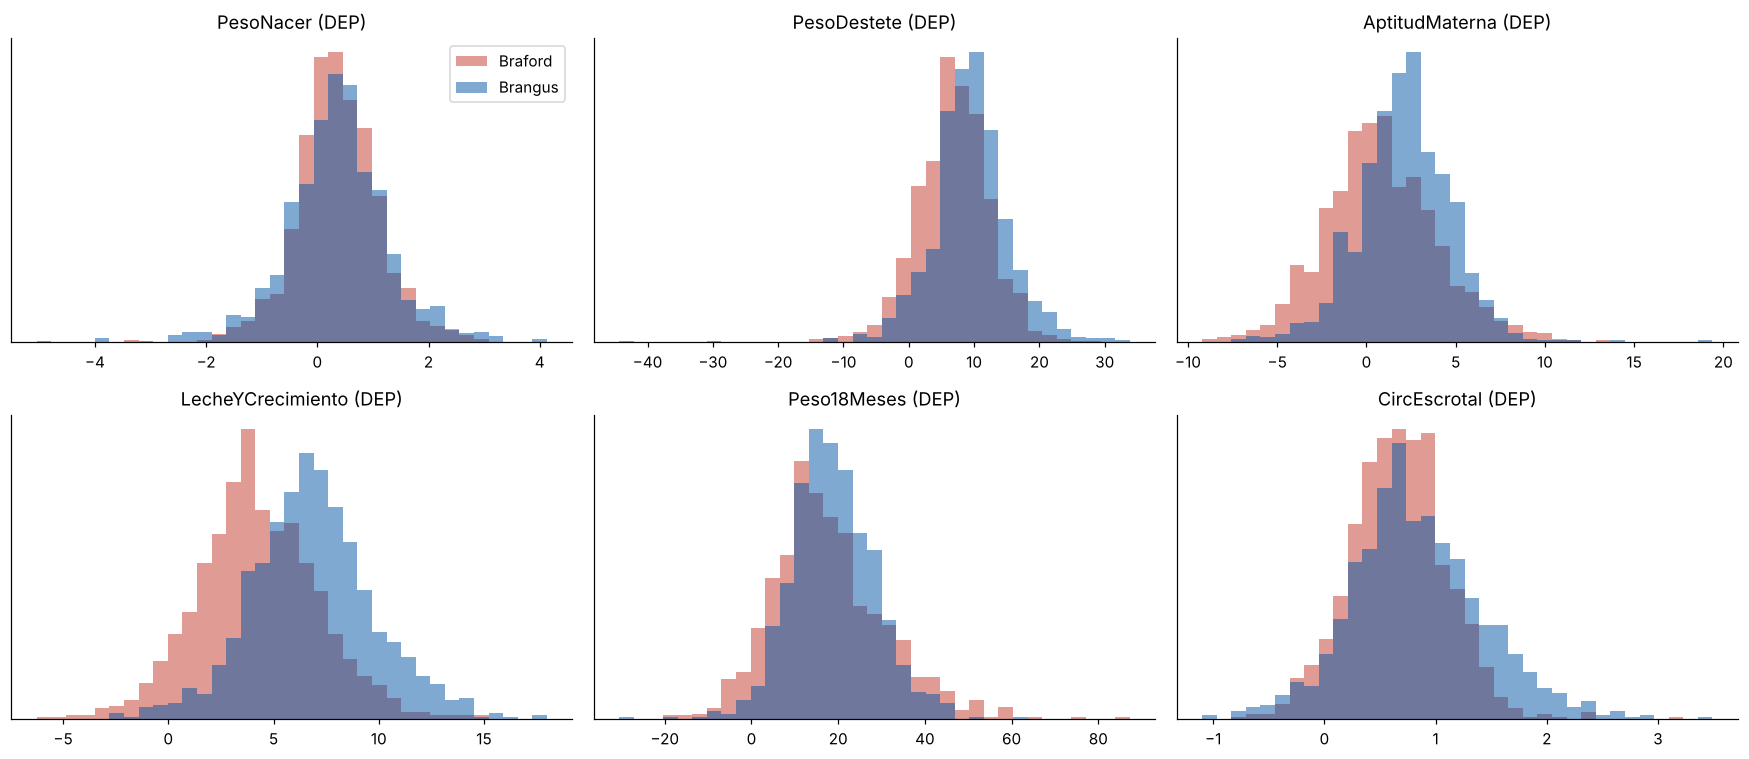

In [6]:
fig, ejes = plt.subplots(2, 3, figsize=(16, 7))
for ax, c in zip(ejes.ravel(), DEP):
    bins = np.histogram_bin_edges(procesado[c].dropna(), bins=35)
    for raza, col in COLOR_RAZA.items():
        ax.hist(procesado.loc[procesado.Raza == raza, c], bins=bins, alpha=0.5, color=col, label=raza, density=True)
    ax.set_title(c.replace("_DEP", " (DEP)")); ax.set_yticks([])
ejes[0, 0].legend()
plt.tight_layout(); fig.savefig(FIG / "tp1_distribuciones.png", bbox_inches="tight"); plt.show()

**Qué vemos.** Distribuciones bastante simétricas, con colas largas en destete y 18 meses: unos pocos toros muy por encima del resto.

### 3.2 · Relación entre las DEP

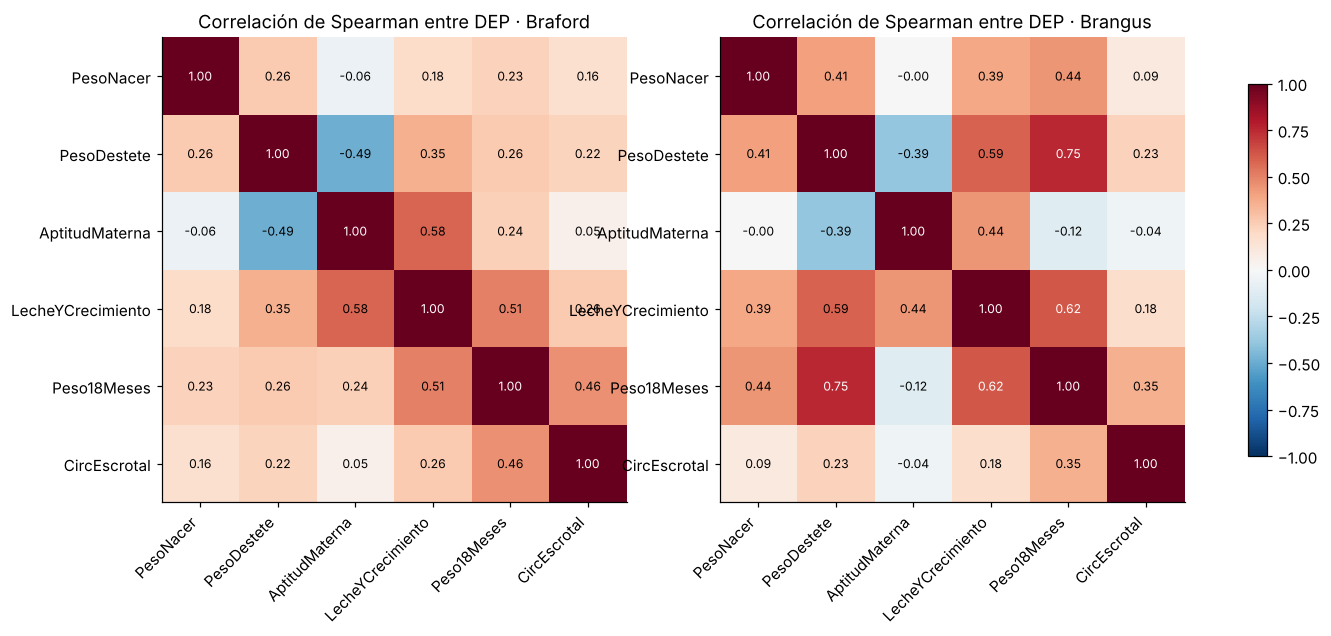

Leche y Crecimiento = Aptitud Materna + ½ Destete: diferencia máxima 0.010


In [7]:
fig, ejes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, raza in zip(ejes, ["Braford", "Brangus"]):
    corr = procesado.loc[procesado.Raza == raza, DEP].corr(method="spearman")
    im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
    etiquetas = [c.replace("_DEP", "") for c in DEP]
    ax.set_xticks(range(len(DEP))); ax.set_xticklabels(etiquetas, rotation=45, ha="right"); ax.set_yticks(range(len(DEP))); ax.set_yticklabels(etiquetas)
    for i in range(len(DEP)):
        for j in range(len(DEP)):
            ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8, color="white" if abs(corr.iloc[i, j]) > 0.6 else "black")
    ax.set_title(f"Correlación de Spearman entre DEP · {raza}")
fig.colorbar(im, ax=ejes, shrink=0.8)
fig.savefig(FIG / "tp1_correlaciones.png", bbox_inches="tight"); plt.show()
lc = procesado["AptitudMaterna_DEP"] + procesado["PesoDestete_DEP"] / 2
print(f"Leche y Crecimiento = Aptitud Materna + ½ Destete: diferencia máxima {np.abs(procesado['LecheYCrecimiento_DEP'] - lc).max():.3f}")

**Qué vemos.**
- La DEP de 18 meses se relaciona sobre todo con la de **destete**, y bastante más en Brangus que en Braford.
- **Leche y Crecimiento es una cuenta:** Aptitud Materna + ½ Destete (la diferencia máxima es 0,01, por redondeo). No aporta información nueva, así que en los modelos de los TP2 y TP3 no la usamos.

### 3.3 · ¿Cuánto respaldo tiene cada DEP?
La precisión dice cuánta información hay detrás de la DEP. La miramos según la cantidad de crías evaluadas.

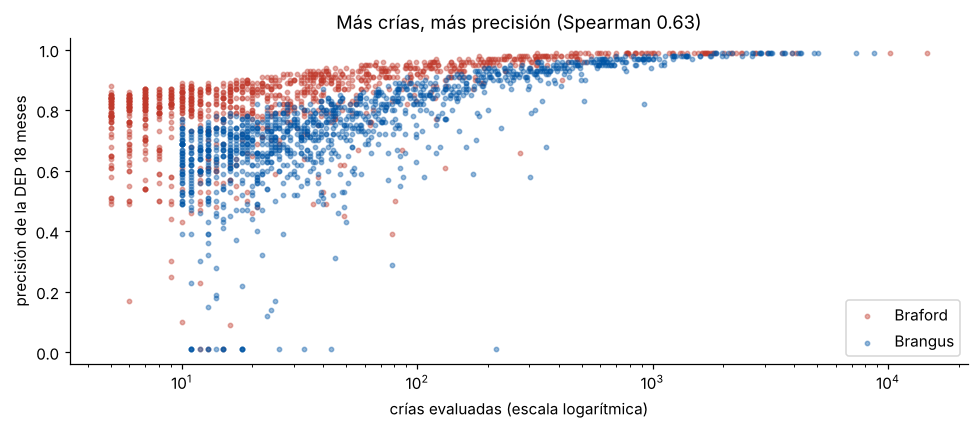

,toros,media,mediana,"% con precisión > 0,90"
N_Crias,,,,
5-10,367,0.747,0.80,0.000
11-30,789,0.693,0.72,1.014
31-100,584,0.795,0.81,19.178
101-1000,493,0.920,0.94,73.225
>1000,96,0.986,0.99,100.000


In [8]:
tramos = pd.cut(procesado["N_Crias"], bins=[4, 10, 30, 100, 1000, procesado["N_Crias"].max()], labels=["5-10", "11-30", "31-100", "101-1000", ">1000"])
tabla_prec = procesado.groupby(tramos, observed=True)["Peso18Meses_PREC"].agg(toros="size", media="mean", mediana="median")
tabla_prec["% con precisión > 0,90"] = procesado.groupby(tramos, observed=True)["Peso18Meses_PREC"].apply(lambda s: (s > 0.90).mean() * 100)
rho = stats.spearmanr(procesado["N_Crias"], procesado["Peso18Meses_PREC"])[0]
fig, ax = plt.subplots(figsize=(9, 4))
for raza, col in COLOR_RAZA.items():
    d = procesado[procesado.Raza == raza]
    ax.scatter(d["N_Crias"], d["Peso18Meses_PREC"], s=8, alpha=0.4, color=col, label=raza)
ax.set_xscale("log"); ax.set_xlabel("crías evaluadas (escala logarítmica)"); ax.set_ylabel("precisión de la DEP 18 meses")
ax.set_title(f"Más crías, más precisión (Spearman {rho:.2f})"); ax.legend()
plt.tight_layout(); fig.savefig(FIG / "tp1_precision_crias.png", bbox_inches="tight"); plt.show()
tabla_prec.round(3)

**Qué vemos.** La precisión crece con las crías (Spearman 0,63): los toros con más de 100 crías tienen casi siempre precisión mayor a 0,90, y los de menos de 30, casi nunca. Esto es lo que motiva todo el proyecto: **un toro joven tiene una DEP de 18 meses poco precisa**, y sería útil anticiparla con información que se conoce antes.

### 3.4 · ¿El RANK 1 es el mejor?

In [9]:
filas = []
for c in ["PesoNacer", "PesoDestete", "AptitudMaterna", "Peso18Meses", "CircEscrotal"]:
    filas.append({"carácter": c, "Spearman DEP vs RANK": stats.spearmanr(procesado[c + "_DEP"], procesado[c + "_RANK"])[0],
                  "DEP media con RANK 1": procesado.loc[procesado[c + "_RANK"] == 1, c + "_DEP"].mean(),
                  "DEP media con RANK 99": procesado.loc[procesado[c + "_RANK"] == 99, c + "_DEP"].mean()})
pd.DataFrame(filas).round(3)

,carácter,Spearman DEP vs RANK,DEP media con RANK 1,DEP media con RANK 99
0,PesoNacer,0.994,-1.637,2.212
1,PesoDestete,-0.981,20.249,-4.977
2,AptitudMaterna,-0.911,8.805,-3.235
3,Peso18Meses,-0.994,42.429,-5.448
4,CircEscrotal,-0.958,1.950,-0.585


**Qué vemos.** En destete, aptitud materna, 18 meses y circunferencia escrotal, RANK 1 es la DEP más alta. En **peso al nacer es al revés**: RANK 1 es la DEP más baja (terneros más livianos, partos más fáciles). Esto lo tenemos que tener en cuenta para no interpretar mal el RANK.

## 4 · La pregunta del TP1: ¿qué toro elegir para más kilos a los 18 meses?
Usamos el criterio de **toro líder** de cada sumario: precisión mínima de la DEP de 18 meses y crías en un mínimo de rodeos (Braford: precisión ≥ 0,75 y 4 rodeos; Brangus: precisión ≥ 0,92 y 5 rodeos). Dentro de los que lo cumplen, el de mayor DEP de 18 meses.

In [10]:
CRITERIO = {"Braford": {"prec": 0.75, "rodeos": 4}, "Brangus": {"prec": 0.92, "rodeos": 5}}
cols = ["Nombre", "Anio_Nacimiento", "N_Crias", "N_Cabanas_Rodeos", "Peso18Meses_DEP", "Peso18Meses_PREC", "Peso18Meses_RANK"]
for raza, g in procesado.groupby("Raza"):
    c = CRITERIO[raza]
    orden = g.sort_values("Peso18Meses_DEP", ascending=False)
    paso1 = orden[orden["Peso18Meses_PREC"] >= c["prec"]]
    lider = paso1[paso1["N_Cabanas_Rodeos"] >= c["rodeos"]]
    print(f"\n{raza}: {len(g)} toros → {len(paso1)} con precisión ≥ {c['prec']} → {len(lider)} además con crías en ≥ {c['rodeos']} rodeos")
    print(f"  Mayor DEP 18 meses sin filtro: {orden.iloc[0]['Nombre']} ({orden.iloc[0]['Peso18Meses_DEP']:.2f} kg, "
          f"{int(orden.iloc[0]['N_Crias'])} crías, precisión {orden.iloc[0]['Peso18Meses_PREC']:.2f})")
    print(f"  Elegido con el criterio de toro líder: {lider.iloc[0]['Nombre']} ({lider.iloc[0]['Peso18Meses_DEP']:.2f} kg, "
          f"{int(lider.iloc[0]['N_Crias'])} crías, precisión {lider.iloc[0]['Peso18Meses_PREC']:.2f})")
    display(lider[cols].head(5))


Braford: 1106 toros → 947 con precisión ≥ 0.75 → 286 además con crías en ≥ 4 rodeos
  Mayor DEP 18 meses sin filtro: GATOPA T321 (87.24 kg, 10 crías, precisión 0.84)
  Elegido con el criterio de toro líder: AMARGO 13249 -T/E- CHELO (58.93 kg, 99 crías, precisión 0.83)


,Nombre,Anio_Nacimiento,N_Crias,N_Cabanas_Rodeos,Peso18Meses_DEP,Peso18Meses_PREC,Peso18Meses_RANK
85,AMARGO 13249 -T/E- CHELO,2022.0,99,9,58.93,0.83,1
3,ARROCERO 6197 GERVASIO ENGREIDO,2016.0,39,4,53.53,0.90,1
184,CARRETERO 36623 T/E KENTUCKY,2020.0,40,4,53.10,0.85,1
562,LEONEL 227 TAGUE,2016.0,8,5,52.74,0.81,1
603,LEONOR J7051 DUCHO GRAPHITE FIV ENTENDIDO,2019.0,8,5,52.44,0.79,1



Brangus: 1223 toros → 218 con precisión ≥ 0.92 → 205 además con crías en ≥ 5 rodeos
  Mayor DEP 18 meses sin filtro: OSIRIS L101 VIKINGO (61.08 kg, 24 crías, precisión 0.75)
  Elegido con el criterio de toro líder: CACTUS 2229 MONCHITO MERLO MAXIMO (45.83 kg, 618 crías, precisión 0.96)


,Nombre,Anio_Nacimiento,N_Crias,N_Cabanas_Rodeos,Peso18Meses_DEP,Peso18Meses_PREC,Peso18Meses_RANK
1292,CACTUS 2229 MONCHITO MERLO MAXIMO,2014.0,618,26,45.83,0.96,1
1791,LAS LILAS 7831-B MAULEON-T/E-,2001.0,768,27,43.15,0.96,1
1893,MC RANSOM 889D69,2016.0,218,28,42.88,0.92,1
1689,GUAYCURU C281,2005.0,773,21,42.49,0.93,1
1910,MORRIS MAXIMO 116-T/E-,2008.0,347,23,41.57,0.93,1


**Qué vemos.** El toro con la DEP más alta de cada raza **no** es el que elegiríamos: GATOPA T321 tiene 87,2 kg pero solo 10 crías en un rodeo, y OSIRIS L101 VIKINGO tiene precisión 0,75 en una raza que exige 0,92. Con el criterio de toro líder quedan **AMARGO 13249 -T/E- CHELO** (Braford, 58,9 kg, 99 crías en 9 rodeos) y **CACTUS 2229 MONCHITO MERLO MAXIMO** (Brangus, 45,8 kg, 618 crías en 26 rodeos). Exigir respaldo "cuesta" 28 kg de DEP en Braford y 15 kg en Brangus, a cambio de un número en el que se puede confiar.

## 5 · Datos para los trabajos siguientes

In [11]:
Path("datos").mkdir(exist_ok=True)
procesado.to_csv("datos/toros_braford_brangus.csv", index=False)
print("Guardado datos/toros_braford_brangus.csv:", procesado.shape, "→ es la base de los TP2, TP3 y TP4")

Guardado datos/toros_braford_brangus.csv: (2329, 28) → es la base de los TP2, TP3 y TP4


## 6 · Conclusiones del TP1
- El archivo quedó limpio y documentado: 2329 toros (1106 Braford y 1223 Brangus), sin duplicados, con el código 1901 resuelto y los faltantes explicados.
- **Cada raza se analiza por separado**, porque las DEP no se comparan entre sumarios.
- La **precisión depende de las crías**: un toro joven tiene una DEP de 18 meses poco confiable.
- Elegir solo por la DEP más alta puede llevar a un toro con muy poco respaldo; con el criterio de toro líder se eligió a CHELO (Braford) y a MONCHITO MERLO MAXIMO (Brangus).
- Queda planteada la pregunta de los TP siguientes: **¿se puede anticipar la DEP de 18 meses con las DEP que se conocen antes?** (regresión, TP2) y **¿se puede anticipar si el toro va a estar en el 10 % superior?** (clasificación, TP3).